# <Center>Chapter7: Data Preprocessing & Data Understanding


---

## Contents

### 1. Data preprocessing with time series dataset

---


### Import Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [7]:
'''import sys
!{sys.executable} -m pip uninstall -y pyarrow
!{sys.executable} -m pip install pyarrow --no-cache-dir'''
#import sys
#!{sys.executable} -mpip install --upgrade pip
'''
import sys

!{sys.executable} -m pip uninstall -y pyarrow pandas
!{sys.executable} -m pip install pandas pyarrow'''

'''import sys

!{sys.executable} -m pip uninstall -y pyarrow pandas fastparquet'''

'''
import sys

!{sys.executable} -m pip install pandas==2.2.3 pyarrow==16.1.0'''

'\nimport sys\n\n!{sys.executable} -m pip install pandas==2.2.3 pyarrow==16.1.0'

### Dataset
Source: https://www.kaggle.com/datasets/guillemservera/global-daily-climate-data?select=cities.csv


- ##### Downloading the Dataset

**There are two options for downloading this dataset:**

- Option 1: Manual Download

  - Download the dataset manually using the link provided above.
  - Save the downloaded files to your local computer.

- Option 2: Download Using Python Code

  - Click the link above to access the dataset.
  - Click the “Download” button.
  - You will see a simple Python code example for downloading the dataset.
  - Copy the code and paste it into your Python or Jupyter notebook file.
  - Run the code to automatically download and store the dataset on your computer.

In [13]:
#The dataset will be downloaded and stored in a directory on your computer.
#The printed path shows where the files are saved.

import kagglehub

# Download latest version
path = kagglehub.dataset_download("guillemservera/global-daily-climate-data")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\U-ser\.cache\kagglehub\datasets\guillemservera\global-daily-climate-data\versions\20


In [14]:
# check the files in the directory
import os
list_dir = os.listdir(path)
list_dir

['cities.csv', 'countries.csv', 'daily_weather.parquet']

- ##### Reading Dataset
  After downloading, reading dataset from csv-files and parquet-file.

In [27]:
countries = pd.read_csv(os.path.join(path, list_dir[0]))
cities = pd.read_csv(os.path.join(path, list_dir[1]))
daily = pd.read_parquet(os.path.join(path, list_dir[2]), engine="fastparquet")

We check the size and column types of all three files before doing anything.

<span style = "color:orange"> Each file plays a different:</span>
  - role daily_weather holds the actual readings
  - cities tells us where each station is located
  - and countries adds continent and population context. 

<span style="color:green"> Understanding what types each column holds helps us spot potential problems early, like a date stored as text or a numeric column that loaded as a category. </span>

We print the shape and dtypes of each file separately.

In [28]:
print('daily:'); print(daily.dtypes)
print()
print('cities:'); print(cities.dtypes)
print()
print('countries:'); print(countries.dtypes)

daily:
station_id                      category
city_name                       category
date                      datetime64[ns]
season                          category
avg_temp_c                       float64
min_temp_c                       float64
max_temp_c                       float64
precipitation_mm                 float64
snow_depth_mm                    float64
avg_wind_dir_deg                 float64
avg_wind_speed_kmh               float64
peak_wind_gust_kmh               float64
avg_sea_level_pres_hpa           float64
sunshine_total_min               float64
dtype: object

cities:
country            str
native_name        str
iso2               str
iso3               str
population     float64
area           float64
capital            str
capital_lat    float64
capital_lng    float64
region             str
continent          str
dtype: object

countries:
station_id        str
city_name         str
country           str
state             str
iso2              str
iso3   

2. Statistical summary

We compute a summary of every column across all three files.

Numbers like the minimum, maximum, and average reveal what each column actually contains. For the daily file, a maximum temperature of 97°C or a minimum of -99°C would immediately flag a data recording error. For countries, a missing population count tells us the lookup table is incomplete.

We call describe() on each file and display the results for review.

In [29]:
display(daily.describe())

,date,avg_temp_c,min_temp_c,max_temp_c,precipitation_mm,snow_depth_mm,avg_wind_dir_deg,avg_wind_speed_kmh,peak_wind_gust_kmh,avg_sea_level_pres_hpa,sunshine_total_min
count,27635763,2.140486e+07,2.191753e+07,2.209642e+07,2.099326e+07,3.427148e+06,3.452568e+06,5.285468e+06,1.121486e+06,4.017157e+06,1.021461e+06
mean,1982-11-29 10:03:03.195926336,1.572252e+01,9.948255e+00,2.015998e+01,2.740569e+00,7.996231e+01,1.820979e+02,1.240827e+01,3.857887e+01,1.015032e+03,3.504399e+02
min,1750-02-01 00:00:00,-7.000000e+01,-9.900000e+01,-9.900000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.610000e+02,0.000000e+00
25%,1965-05-06 00:00:00,8.300000e+00,2.800000e+00,1.200000e+01,0.000000e+00,0.000000e+00,8.600000e+01,7.500000e+00,2.630000e+01,1.010300e+03,5.400000e+01
50%,1988-02-04 00:00:00,1.790000e+01,1.110000e+01,2.230000e+01,0.000000e+00,0.000000e+00,1.910000e+02,1.090000e+01,3.530000e+01,1.014700e+03,3.460000e+02
75%,2007-01-25 00:00:00,2.570000e+01,1.920000e+01,3.020000e+01,1.000000e+00,2.000000e+01,2.710000e+02,1.570000e+01,4.640000e+01,1.019800e+03,5.940000e+02
max,2023-09-05 00:00:00,5.040000e+01,6.420000e+01,9.700000e+01,1.000000e+03,9.710000e+03,3.600000e+02,1.763000e+02,4.392000e+02,5.852700e+03,1.302000e+03
std,NaN,1.202205e+01,1.155787e+01,1.249478e+01,9.791887e+00,3.500756e+02,1.051996e+02,7.054249e+00,2.010951e+01,8.520450e+00,2.815142e+02


In [30]:
display(cities.describe(include='all'))

,country,native_name,iso2,iso3,population,area,capital,capital_lat,capital_lng,region,continent
count,214,213,213,214,2.100000e+02,2.070000e+02,212,212.000000,212.000000,205,206
unique,214,213,212,213,NaN,NaN,211,NaN,NaN,24,7
top,Afghanistan,افغانستان,GB,GBR,NaN,NaN,Kingston,NaN,NaN,Eastern Africa,Africa
freq,1,1,2,2,NaN,NaN,2,NaN,NaN,19,53
mean,NaN,NaN,NaN,NaN,3.365144e+07,6.537604e+05,NaN,18.812330,16.545432,NaN,NaN
std,NaN,NaN,NaN,NaN,1.330461e+08,1.866909e+06,NaN,26.590545,69.625088,NaN,NaN
min,NaN,NaN,NaN,NaN,3.000000e+01,2.020000e+00,NaN,-54.283545,-176.174022,NaN,NaN
25%,NaN,NaN,NaN,NaN,7.572605e+05,1.306600e+04,NaN,2.874467,-13.375923,NaN,NaN
50%,NaN,NaN,NaN,NaN,6.315500e+06,1.098840e+05,NaN,18.025227,16.725786,NaN,NaN
75%,NaN,NaN,NaN,NaN,2.268378e+07,4.817710e+05,NaN,41.315970,47.637577,NaN,NaN


In [12]:
display(countries.describe(include='all'))

,country,native_name,iso2,iso3,population,area,capital,capital_lat,capital_lng,region,continent
count,214,213,213,214,2.100000e+02,2.070000e+02,212,212.000000,212.000000,205,206
unique,214,213,212,213,NaN,NaN,211,NaN,NaN,24,7
top,Afghanistan,افغانستان,GB,GBR,NaN,NaN,Kingston,NaN,NaN,Eastern Africa,Africa
freq,1,1,2,2,NaN,NaN,2,NaN,NaN,19,53
mean,NaN,NaN,NaN,NaN,3.365144e+07,6.537604e+05,NaN,18.812330,16.545432,NaN,NaN
std,NaN,NaN,NaN,NaN,1.330461e+08,1.866909e+06,NaN,26.590545,69.625088,NaN,NaN
min,NaN,NaN,NaN,NaN,3.000000e+01,2.020000e+00,NaN,-54.283545,-176.174022,NaN,NaN
25%,NaN,NaN,NaN,NaN,7.572605e+05,1.306600e+04,NaN,2.874467,-13.375923,NaN,NaN
50%,NaN,NaN,NaN,NaN,6.315500e+06,1.098840e+05,NaN,18.025227,16.725786,NaN,NaN
75%,NaN,NaN,NaN,NaN,2.268378e+07,4.817710e+05,NaN,41.315970,47.637577,NaN,NaN


3. Visualize the distribution of each column

We plot the shape of every numeric column in the daily weather file.

A summary table only gives single numbers it cannot show whether values are concentrated in one range, skewed heavily in one direction, or split into separate groups. A column where nearly all values are zero but a few reach 1000 looks very different from a bell-shaped one, and both require different handling strategies.

We use histograms for all numeric columns. 

<span style="color:red"> Cities and countries are small lookup tables, so we skip plotting them. </span>

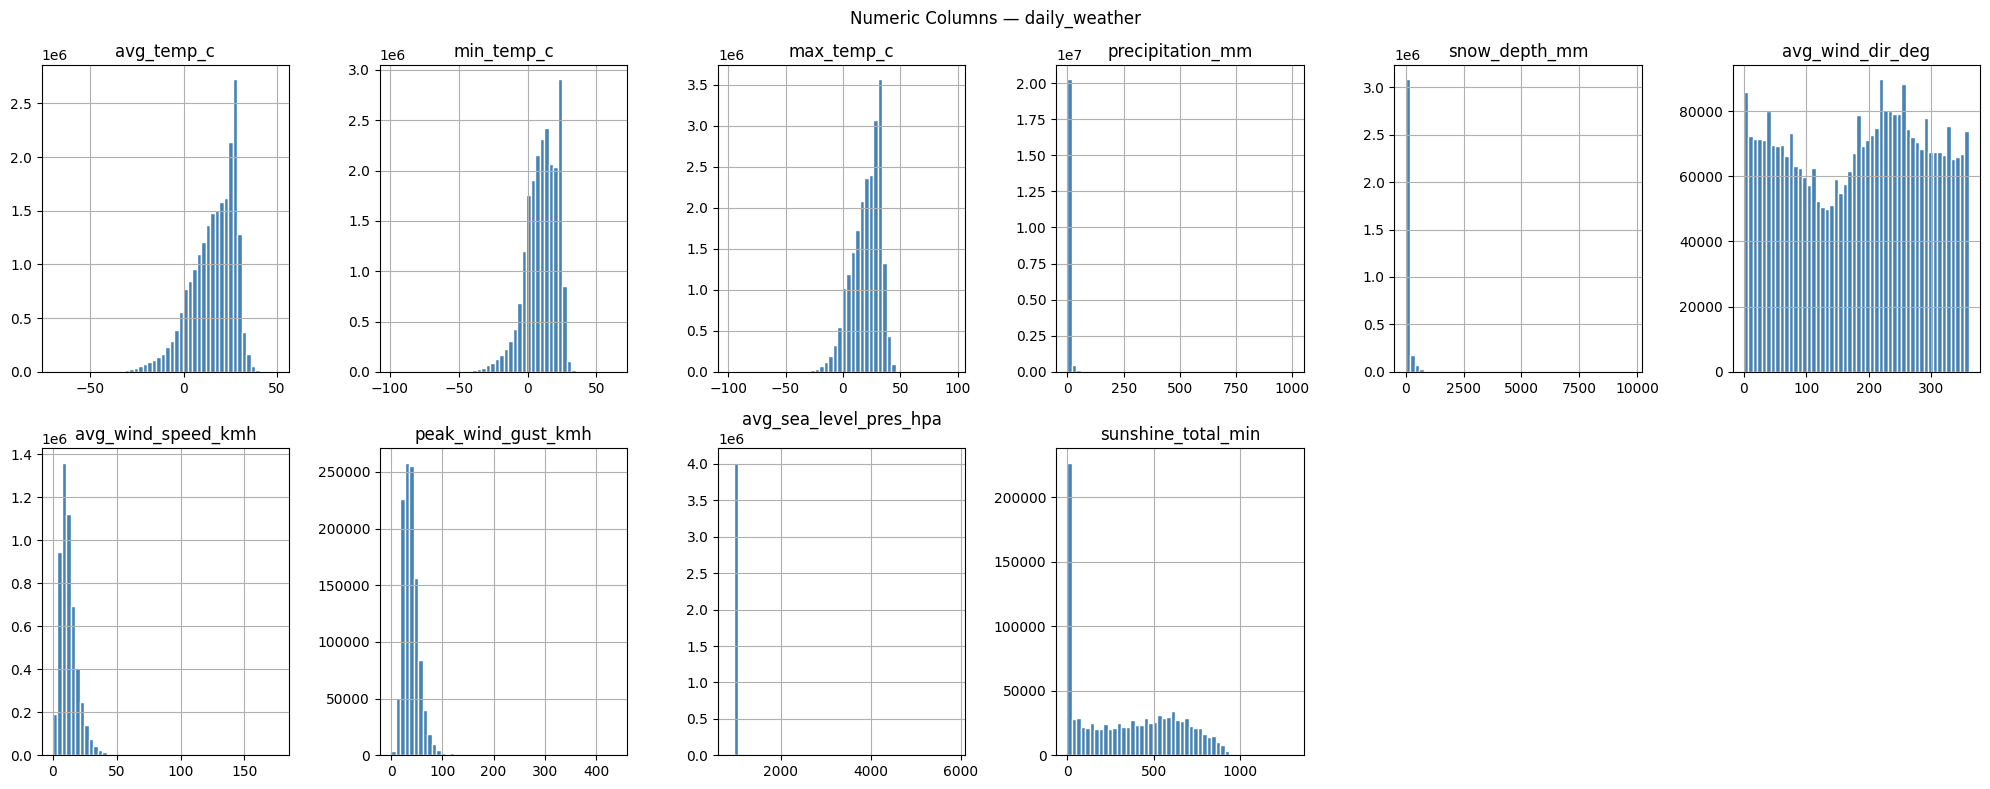

In [31]:
num_cols = daily.select_dtypes(include='number').columns

fig, axes = plt.subplots(2, len(num_cols)//2 + 1, figsize=(20, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    daily[col].dropna().hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
for ax in axes[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Numeric Columns — daily_weather')
plt.tight_layout(); plt.show()

4. Data quality issues

<span style = "color:green">We check for duplicate rows and duplicate key values across all three files.</span>

In the daily file, a duplicate row means the same station recorded the same day twice which would double-count that reading and inflate averages. In the cities and countries files, a duplicate station_id or iso3 would cause the merge to produce extra rows, silently multiplying records in ways that are hard to detect later.

We check full row duplicates for daily, and key-level duplicates for the two lookup files.

In [33]:
print('Duplicates — daily   :', daily.duplicated().sum())
print('Duplicates — cities  :', cities.duplicated().sum())
print('Duplicates — countries:', countries.duplicated().sum())
print()
print('Duplicate station_id in cities :', cities['station_id'].duplicated().sum())
print('Duplicate iso3 in countries    :', countries['iso3'].duplicated().sum())

# drop duplicate rows in daily — same station, same date recorded twice
daily = daily.drop_duplicates().reset_index(drop=True)
print('\ndaily after dedup:', daily.shape)

Duplicates — daily   : 21280
Duplicates — cities  : 0
Duplicates — countries: 0



KeyError: 'station_id'

---

#### B. Handling Missing Data

1. Percentage of missing values per column

We compute what percentage of each column is missing.

With 27 million rows, even a small percentage represents a huge number of missing readings. But a column at 96% missing like sunshine duration is nearly empty and cannot be used. Sorting by percentage makes it immediately clear which columns need to be dropped versus which can be filled.

We divide the null count per column by the total rows and sort from highest to lowest.

In [16]:
na_pct = daily.isnull().sum() / len(daily) * 100
na_pct.sort_values(ascending=False)

sunshine_total_min        96.300995
peak_wind_gust_kmh        95.938776
snow_depth_mm             87.589310
avg_wind_dir_deg          87.521237
avg_sea_level_pres_hpa    85.475299
avg_wind_speed_kmh        80.896278
precipitation_mm          24.014688
avg_temp_c                22.563910
min_temp_c                20.698682
max_temp_c                20.049381
city_name                  0.050673
station_id                 0.000000
date                       0.000000
season                     0.000000
dtype: float64

2. Drop columns above 80% missing

We remove columns where more than 80% of the values are absent.

A column like peak wind gust at 96% missing means we only have data for 4% of all days across all stations mostly from a handful of modern, well-equipped stations. Trying to fill or use such a sparse column would mean inventing most of the data, which does more harm than good.

We collect the column names above the threshold and drop them all at once.

In [17]:
drop_cols = na_pct[na_pct > 80].index.tolist()
print('Dropping:', drop_cols)
daily = daily.drop(columns=drop_cols)

Dropping: ['snow_depth_mm', 'avg_wind_dir_deg', 'avg_wind_speed_kmh', 'peak_wind_gust_kmh', 'avg_sea_level_pres_hpa', 'sunshine_total_min']


3. NA_list and NoNA_list

We split the remaining columns into two groups those with missing values and those without.

This separation lets us use the complete columns as a reference point. If removing rows with missing values changes the shape or average of a complete column, it means the missing rows were not scattered randomly they represented a specific subset of the data.

We build two lists from the percentage table: any column above zero goes into NA_list, the rest into NoNA_list.

In [18]:
na_pct2  = daily.isnull().sum() / len(daily) * 100
NA_list   = na_pct2[na_pct2 > 0].index.tolist()
NoNA_list = na_pct2[na_pct2 == 0].index.tolist()
print('NA_list  :', NA_list)
print('NoNA_list:', NoNA_list)

NA_list  : ['city_name', 'avg_temp_c', 'min_temp_c', 'max_temp_c', 'precipitation_mm']
NoNA_list: ['station_id', 'date', 'season']


4. Distribution before and after removing rows with NAs

We plot the weather columns before and after removing rows that contain missing values.

If the histogram shapes look the same in both versions, the removed rows were spread evenly across the data. If the shape changes for example, the temperature distribution becomes noticeably colder it would mean the missing rows came disproportionately from warm regions or seasons, and dropping them would leave us with a skewed picture.

We drop rows based on the NA list and plot both versions side by side for each numeric column.

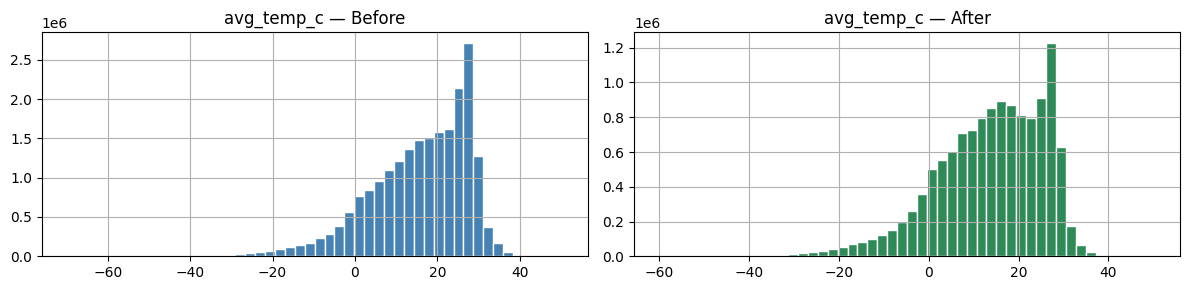

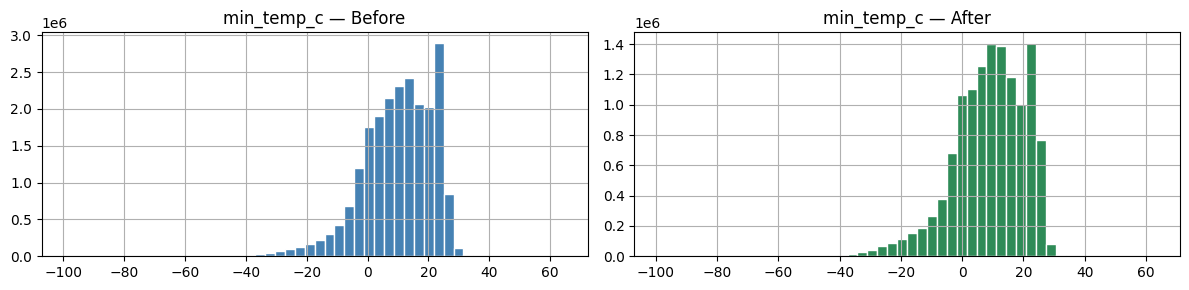

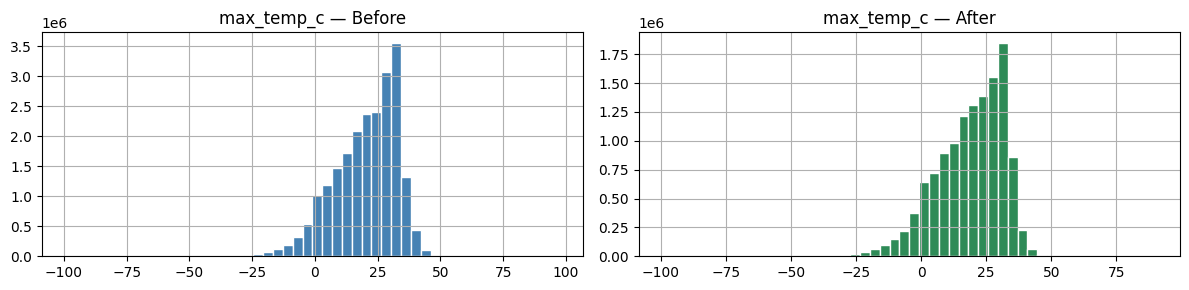

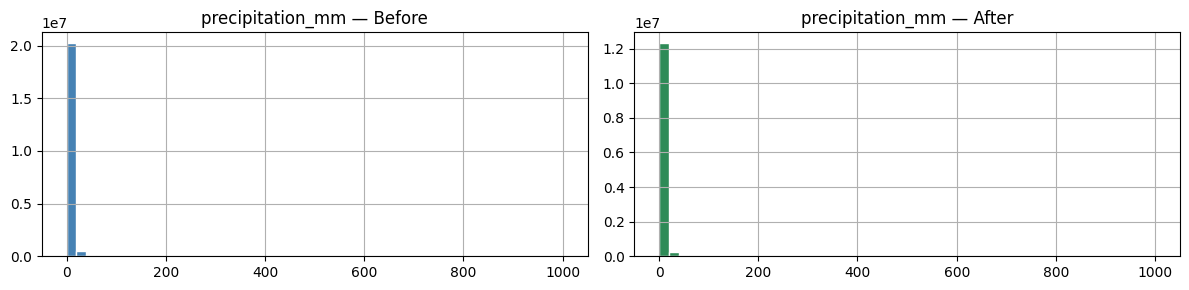

In [19]:
daily_dropped = daily.dropna(subset=NA_list)

# all numeric columns have NAs — compare them directly, not through NoNA_list
num_cols_daily = daily.select_dtypes(include='number').columns

for col in num_cols_daily:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    daily[col].hist(bins=50, ax=axes[0], color='steelblue', edgecolor='white')
    axes[0].set_title(f'{col} — Before')
    daily_dropped[col].hist(bins=50, ax=axes[1], color='seagreen', edgecolor='white')
    axes[1].set_title(f'{col} — After')
    plt.tight_layout(); plt.show()

5. Statistical summary before and after

We compute the summary table for the weather columns before and after removing rows with missing values.

The plots show the overall shape, but they can miss small shifts in the center or spread. The table gives us exact numbers if the mean temperature barely moves after dropping rows, we have stronger numerical evidence that the removal did not distort the data.

We call describe() on both versions and display them one after the other for direct comparison.

In [20]:
print('Before:')
display(daily[num_cols_daily].describe())
print('After:')
display(daily_dropped[num_cols_daily].describe())

Before:


,avg_temp_c,min_temp_c,max_temp_c,precipitation_mm
count,2.138358e+07,2.189865e+07,2.207795e+07,2.098295e+07
mean,1.571067e+01,9.936488e+00,2.015009e+01,2.740476e+00
std,1.202205e+01,1.155576e+01,1.249525e+01,9.786115e+00
min,-7.000000e+01,-9.900000e+01,-9.900000e+01,0.000000e+00
25%,8.300000e+00,2.800000e+00,1.200000e+01,0.000000e+00
50%,1.780000e+01,1.110000e+01,2.220000e+01,0.000000e+00
75%,2.570000e+01,1.920000e+01,3.020000e+01,1.000000e+00
max,5.040000e+01,6.420000e+01,9.700000e+01,1.000000e+03


After:


,avg_temp_c,min_temp_c,max_temp_c,precipitation_mm
count,1.271193e+07,1.271193e+07,1.271193e+07,1.271193e+07
mean,1.364202e+01,8.859458e+00,1.878745e+01,2.536019e+00
std,1.209782e+01,1.185421e+01,1.276912e+01,9.086352e+00
min,-6.010000e+01,-9.900000e+01,-9.900000e+01,0.000000e+00
25%,6.100000e+00,1.700000e+00,1.040000e+01,0.000000e+00
50%,1.520000e+01,1.000000e+01,2.080000e+01,0.000000e+00
75%,2.350000e+01,1.800000e+01,2.920000e+01,1.000000e+00
max,5.040000e+01,6.300000e+01,9.000000e+01,1.000000e+03


6. Nature of missing values and handling strategy

We check whether the missing values are linked to any pattern in the data.

Looking at the season distribution, the proportions are nearly identical between rows with and without missing temperature values each season accounts for about 25% in both groups. This tells us the missingness is not tied to season, region, or any other variable we can observe. That is the definition of MCAR Missing Completely At Random. The data is simply absent, not absent for a reason.

Because the missingness is random, we can fill gaps without introducing bias. We carry each station's last known reading forward in time to fill the gap, then fill any remaining gaps at the very start of a station's record by looking forward instead. Any station that has no readings at all gets dropped entirely.

In [21]:
# check if missingness clusters by season — a sign it is not random
daily['is_missing'] = daily['avg_temp_c'].isnull().astype(int)
print(daily.groupby('is_missing')['season'].value_counts(normalize=True).unstack().round(3))
daily.drop(columns='is_missing', inplace=True)

season      Autumn  Spring  Summer  Winter
is_missing                                
0            0.248   0.253   0.252   0.248
1            0.249   0.252   0.252   0.248


In [22]:
daily = daily.sort_values(['station_id', 'date']).reset_index(drop=True)

# carry the last known value forward within each station
daily[NA_list] = daily.groupby('station_id')[NA_list].ffill()
# fill any remaining NAs at the start of a station with the next known value
daily[NA_list] = daily.groupby('station_id')[NA_list].bfill()
# drop rows that still have NAs — stations with no data at all
daily = daily.dropna(subset=NA_list).reset_index(drop=True)

print('Remaining NAs:', daily.isnull().sum().sum())
print('Shape after fill:', daily.shape)

/var/folders/fw/jz833n056ts6528df38512mh0000gn/T/ipykernel_44999/4089127121.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  daily[NA_list] = daily.groupby('station_id')[NA_list].ffill()
/var/folders/fw/jz833n056ts6528df38512mh0000gn/T/ipykernel_44999/4089127121.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  daily[NA_list] = daily.groupby('station_id')[NA_list].bfill()


Remaining NAs: 0
Shape after fill: (27600490, 8)


---

#### C. Merge the Three Files

1. Clean duplicates in lookup tables

We remove duplicate keys from the cities and countries files before joining them to the daily data.

If a station_id appears twice in the cities file, every row in daily_weather for that station would be duplicated when we merge silently doubling the data for those locations with no error or warning. The same problem occurs with duplicate iso3 codes in countries. Cleaning the lookup tables first prevents this entirely.

We deduplicate on station_id for cities and iso3 for countries, keeping the first occurrence.

In [23]:
cities    = cities.drop_duplicates(subset='station_id').reset_index(drop=True)
countries = countries.drop_duplicates(subset='iso3').reset_index(drop=True)
print('cities after dedup   :', cities.shape)
print('countries after dedup:', countries.shape)

cities after dedup   : (1227, 8)
countries after dedup: (213, 11)


2. Join daily_weather with cities

We attach city and location information to each daily weather record.

The daily file only knows about station IDs it has no country, latitude, or longitude on its own. Without this join, we cannot group stations by region, filter to a specific country, or use geographic coordinates as model inputs.

We merge on station_id using a left join so every weather record is kept, even if its station ID has no match in the cities file.

In [24]:
keep_cities = ['station_id', 'country', 'iso2', 'iso3', 'latitude', 'longitude']
df = daily.merge(cities[keep_cities], on='station_id', how='left')
print('After cities merge:', df.shape)

After cities merge: (27600490, 13)


3. Join with countries

We add continent, region, and population from the countries file.

The cities file tells us which country each station belongs to, but not which continent or broader region. Adding that level of geography lets us compare climate patterns between Africa and Europe, or between Southeast Asia and the Nordic Countries.

We merge on iso3 using a left join to preserve all weather records regardless of whether the country has a match.

In [25]:
keep_countries = ['iso3', 'continent', 'region', 'population', 'area']
df = df.merge(countries[keep_countries], on='iso3', how='left')
print('After countries merge:', df.shape)
df.head()

After countries merge: (27600490, 17)


,station_id,city_name,date,season,avg_temp_c,min_temp_c,max_temp_c,precipitation_mm,country,iso2,iso3,latitude,longitude,continent,region,population,area
0,01008,Longyearbyen,1975-08-01,Summer,-0.6,2.3,5.8,1.0,Svalbard and Jan Mayen Islands,SJ,SJM,78.216684,15.549996,Europe,Nordic Countries,2562.0,NaN
1,01008,Longyearbyen,1975-08-02,Summer,-0.6,3.5,5.6,1.0,Svalbard and Jan Mayen Islands,SJ,SJM,78.216684,15.549996,Europe,Nordic Countries,2562.0,NaN
2,01008,Longyearbyen,1975-08-03,Summer,-0.6,4.4,6.3,0.0,Svalbard and Jan Mayen Islands,SJ,SJM,78.216684,15.549996,Europe,Nordic Countries,2562.0,NaN
3,01008,Longyearbyen,1975-08-04,Summer,-0.6,4.4,7.9,0.0,Svalbard and Jan Mayen Islands,SJ,SJM,78.216684,15.549996,Europe,Nordic Countries,2562.0,NaN
4,01008,Longyearbyen,1975-08-05,Summer,-0.6,2.4,7.0,1.0,Svalbard and Jan Mayen Islands,SJ,SJM,78.216684,15.549996,Europe,Nordic Countries,2562.0,NaN


4. Verify the merge

We check how many records came out of the merge without a continent value.

A left join keeps every row from the left table even when there is no match those unmatched rows get a blank continent. A large blank count means some stations belong to territories or small islands that are missing from the countries file, so we know their data will lack geographic context.

We count null continent values and show a breakdown of station count per continent to see the coverage.

In [26]:
print('Rows with no continent info:', df['continent'].isnull().sum())
print()
print('Station count by continent:')
print(df.groupby('continent')['station_id'].nunique().sort_values(ascending=False))

Rows with no continent info: 464805

Station count by continent:
continent
Asia             382
Europe           315
Africa           209
South America    137
North America    123
Oceania           32
Antarctica         2
Name: station_id, dtype: int64


---

#### D. Time Series Preparation

1. Parse date and sort

We ensure the date column is recognised as a proper date type and that all rows are in chronological order.

When dates are stored as text, pandas cannot sort them correctly, resample them by month, or compute the number of days between two entries. Everything in time series analysis depends on dates being both the right type and in the right order.

We convert using to_datetime() and sort by station then date so each station's records run from oldest to newest.

In [27]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['station_id', 'date']).reset_index(drop=True)
print('Date range:', df['date'].min(), '--', df['date'].max())

Date range: 1750-02-01 00:00:00 -- 2023-09-05 00:00:00


2. Filter to 2000–2023

We keep only records from the year 2000 onwards.

The dataset reaches back to 1750, but most of those early records come from just a handful of European stations with limited equipment. Keeping pre-2000 data would make the dataset look geographically unbalanced heavily European, heavily incomplete which would skew both the analysis and any model trained on it. From 2000 onwards, coverage across continents is much more consistent.

We filter by year and reset the index so row numbers run cleanly from zero.

In [28]:
df = df[df['date'].dt.year >= 2000].reset_index(drop=True)
print('Shape after filter:', df.shape)
print('Date range:', df['date'].min(), '--', df['date'].max())
print('Unique stations:', df['station_id'].nunique())

Shape after filter: (9525647, 17)
Date range: 2000-01-01 00:00:00 -- 2023-09-05 00:00:00
Unique stations: 1226


3. Check time gaps per station

We count how many times each station goes silent for more than one day at a stretch.

A gap is different from a missing value the entire row is absent, not just one number in a row. Some time series models assume records arrive every day without interruption, so knowing which stations have long silences helps us decide whether to fill in the missing days or restrict the analysis to stations with continuous records.

We compute the day difference between consecutive dates per station and count any jump larger than one day.

In [29]:
def count_gaps(group):
    dates = group['date'].sort_values()
    return (dates.diff().dt.days > 1).sum()

gaps = df.groupby('station_id').apply(count_gaps)
print('Stations with at least one gap:', (gaps > 0).sum())
print('Max gaps in one station       :', gaps.max())
print()
print('Gap distribution:')
print(gaps[gaps > 0].describe().round(1))

Stations with at least one gap: 997
Max gaps in one station       : 1087

Gap distribution:
count     997.0
mean      141.8
std       208.9
min         1.0
25%         5.0
50%        31.0
75%       214.0
max      1087.0
dtype: float64


/var/folders/fw/jz833n056ts6528df38512mh0000gn/T/ipykernel_44999/4096109018.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gaps = df.groupby('station_id').apply(count_gaps)


4. Resample to monthly averages

We compress the daily records into one average row per station per month.

Day-to-day weather fluctuates a lot a single cold night in July does not change the overall summer picture. Monthly averages smooth that short-term noise and reveal the slower trends we actually care about, like whether temperatures are rising over years or which months are wettest. As a bonus, the dataset shrinks from roughly 9 million rows to around 300,000, which makes everything faster.

We group by station and calendar month using a Grouper, then take the mean of all numeric columns.

In [30]:
df = df.set_index('date')
num_cols = df.select_dtypes(include='number').columns

# average all numeric columns per station per month
monthly = (df.groupby(['station_id', 'city_name', 'continent', 'region',
                        pd.Grouper(freq='ME')])[num_cols]
             .mean()
             .reset_index())

print('Monthly shape:', monthly.shape)
monthly.head()

/var/folders/fw/jz833n056ts6528df38512mh0000gn/T/ipykernel_44999/91698941.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly = (df.groupby(['station_id', 'city_name', 'continent', 'region',


: 

---

#### E. Analyzing Connections Between Columns

1. Temperature by season

We compare average temperature across the four seasons.

Summer should be warmer than winter that is true almost everywhere on earth. But the dataset covers stations from the Arctic to the tropics, so the pattern may be blurrier than expected when all stations are mixed together. We want to confirm that the seasonal signal still shows up clearly in the combined data.

We use a box plot with seasons ordered from Winter to Autumn so the natural progression is readable left to right.

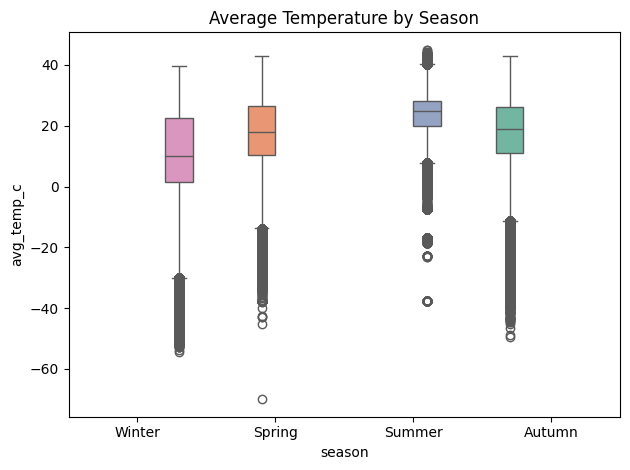

In [24]:
order = ['Winter', 'Spring', 'Summer', 'Autumn']
sns.boxplot(data=df.reset_index(), x='season', y='avg_temp_c',
            hue='season', order=order, palette='Set2', legend=False)
plt.title('Average Temperature by Season')
plt.tight_layout(); plt.show()

2. Temperature by continent

We compare average temperature across the seven continents in the dataset.

Africa and Asia are mostly warm year-round, while Europe and North America have more pronounced seasons, and Antarctica sits far below the rest. This plot gives us a geographic sense of the data's range before we build any model and helps us decide whether continent is a meaningful feature to include.

We sort the box plot by median temperature so continents are arranged from coldest to warmest, making the pattern immediately clear.

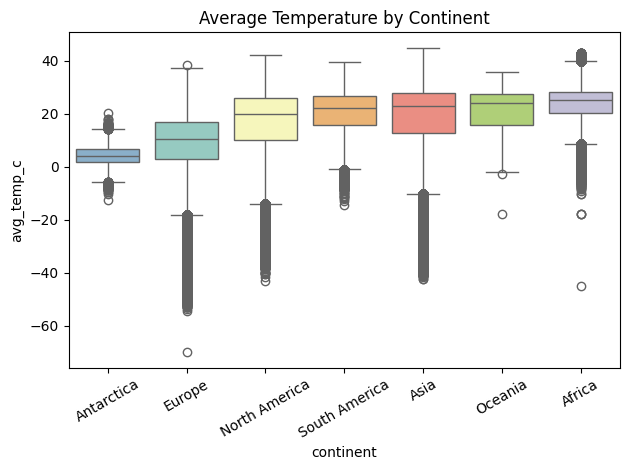

In [25]:
df_reset = df.reset_index()
order = df_reset.groupby('continent')['avg_temp_c'].median().sort_values().index
sns.boxplot(data=df_reset, x='continent', y='avg_temp_c',
            hue='continent', order=order, palette='Set3', legend=False)
plt.xticks(rotation=30)
plt.title('Average Temperature by Continent')
plt.tight_layout(); plt.show()

3. Precipitation distribution

We look at the distribution of daily rainfall across all stations.

Precipitation is one of the most unevenly distributed weather variables the vast majority of days record zero or near-zero rainfall, while a handful of tropical or storm days record extreme values. This heavy skew matters because it affects how we handle outliers and whether we might want to transform this column before modeling.

We plot a histogram of precipitation values after dropping missing entries to see the full shape of the distribution.

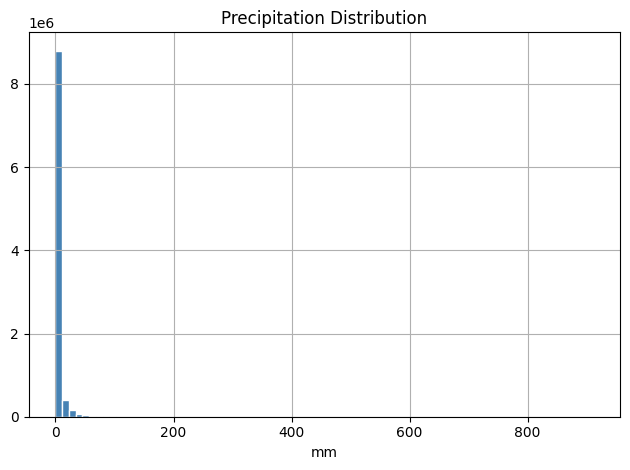

In [26]:
df.reset_index()['precipitation_mm'].dropna().hist(bins=80, color='steelblue', edgecolor='white')
plt.title('Precipitation Distribution')
plt.xlabel('mm'); plt.tight_layout(); plt.show()

4. Rolling statistics — example station

We show how temperature evolves over time for a single city.

Plotting raw daily values produces a noisy zigzag that makes it hard to see longer trends. A 30-day rolling average smooths that noise and makes the seasonal cycle — warm summers, cold winters, the gradual shift between them much more visible. The shaded band around it shows how stable the temperature was during each period.

We pick the station with the most records so we have a long, continuous view, then compute and plot the rolling mean and standard deviation together.

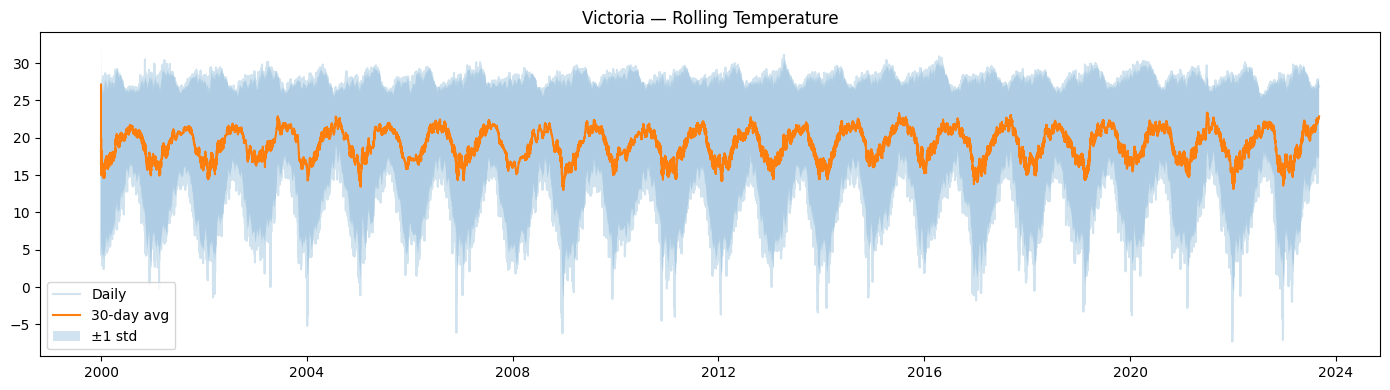

In [27]:
df_reset = df.reset_index()
top_station = df_reset.groupby('city_name').size().idxmax()
example = df_reset[df_reset['city_name'] == top_station].copy().sort_values('date')

example['rolling_avg'] = example['avg_temp_c'].rolling(30, min_periods=1).mean()
example['rolling_std'] = example['avg_temp_c'].rolling(30, min_periods=1).std()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(example['date'], example['avg_temp_c'], alpha=0.2, label='Daily')
ax.plot(example['date'], example['rolling_avg'], label='30-day avg', linewidth=1.5)
ax.fill_between(example['date'],
                example['rolling_avg'] - example['rolling_std'],
                example['rolling_avg'] + example['rolling_std'],
                alpha=0.2, label='±1 std')
ax.set_title(f'{top_station} — Rolling Temperature')
ax.legend(); plt.tight_layout(); plt.show()

---

#### ML Preparation

We work on the monthly table from here. It is smaller, less noisy, and more suitable for model training than the raw daily data.

1. Outlier detection and handling

We find and limit extreme values in each numeric column of the monthly table.

Even after monthly averaging, some values remain extreme a station reporting an average monthly temperature of 60°C, or precipitation of 1000mm in one month. These outliers can dominate the model's learning and pull predictions away from what most stations actually experience.

We use the IQR method to find where the normal range ends and clip anything beyond it to the boundary instead of deleting the row.

Extreme values can pull the model in the wrong direction. We find them and bring them back to a reasonable limit instead of removing the row.

avg_temp_c: 3580 outliers
min_temp_c: 3207 outliers
max_temp_c: 4276 outliers
precipitation_mm: 25792 outliers
latitude: 2695 outliers
longitude: 3674 outliers
population: 35098 outliers
area: 48461 outliers


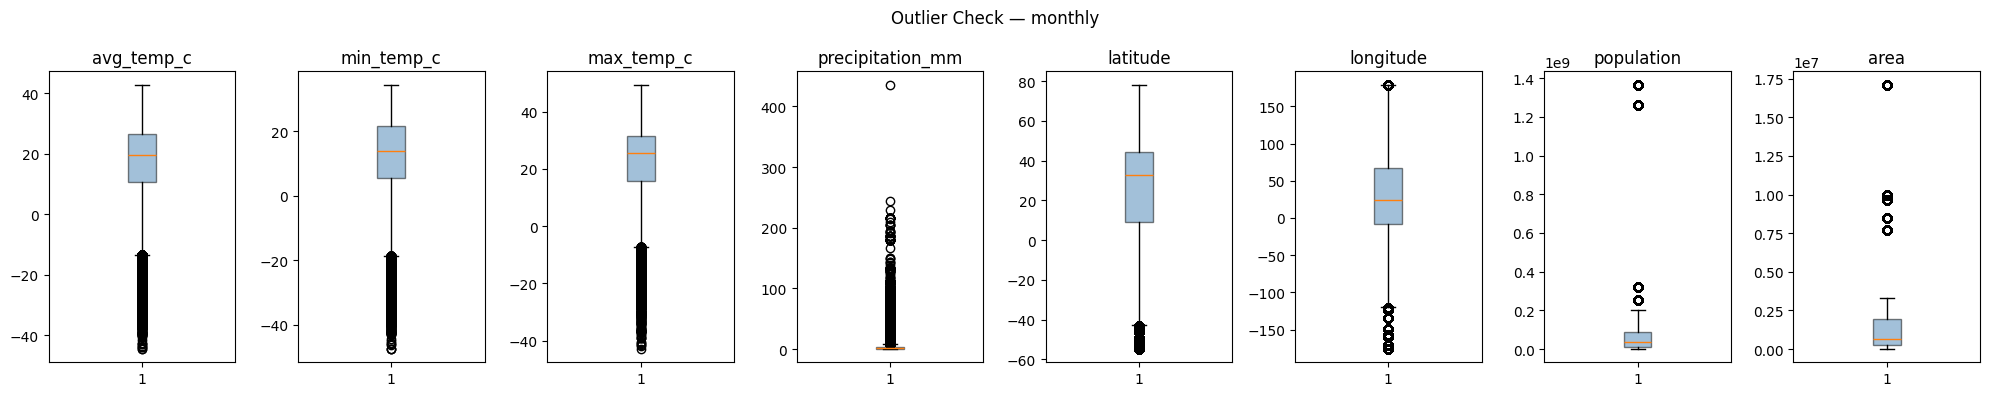

In [28]:
num_cols = monthly.select_dtypes(include='number').columns

for col in num_cols:
    Q1 = monthly[col].quantile(0.25)
    Q3 = monthly[col].quantile(0.75)
    IQR = Q3 - Q1
    n = ((monthly[col] < Q1 - 1.5*IQR) | (monthly[col] > Q3 + 1.5*IQR)).sum()
    print(f'{col}: {n} outliers')

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(monthly[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor='steelblue', alpha=0.5))
    ax.set_title(col)
plt.suptitle('Outlier Check — monthly')
plt.tight_layout(); plt.show()

In [29]:
data_ml = monthly.copy()
for col in num_cols:
    Q1 = data_ml[col].quantile(0.25)
    Q3 = data_ml[col].quantile(0.75)
    IQR = Q3 - Q1
    data_ml[col] = data_ml[col].clip(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

2. Encode categorical variables

We convert geographic categories into numbers and remove identifier columns that the model cannot use.

A model cannot interpret the word "Europe" or "Nordic Countries" it can only perform arithmetic. Every text column must be transformed first. We also remove station ID, city name, and date because they are identifiers, not features a model should not learn that station 01008 has a certain temperature; it should learn from latitude, longitude, and season instead.

We use one-hot encoding for continent and region, sort by date before dropping it to lock in the time order, then remove the identifier columns.

In [30]:
# continent and region have no natural order — use one-hot encoding
data_ml = pd.get_dummies(data_ml, columns=['continent', 'region'], drop_first=True)

# sort by date before dropping it — time order must be preserved for the split
data_ml = data_ml.sort_values('date').reset_index(drop=True)
data_ml = data_ml.drop(columns=['station_id', 'city_name', 'date'], errors='ignore')

print(data_ml.shape)
data_ml.head()

(321996, 37)


,avg_temp_c,min_temp_c,max_temp_c,precipitation_mm,latitude,longitude,population,area,continent_Antarctica,continent_Asia,...,region_North America,region_Northern Africa,region_Polynesia,region_South America,region_Southeast Asia,region_Southern Africa,region_Southern Europe,region_Southern and Central Asia,region_Western Africa,region_Western Europe
0,-8.506452,-11.483871,-5.919355,0.290323,78.216684,15.549996,2562.0,NaN,False,False,...,False,False,False,False,False,False,False,False,False,False
1,-3.478261,-6.278261,-1.121739,4.365217,47.005024,28.857711,3557600.0,33846.0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,20.544444,15.566667,28.622222,0.644444,-3.363812,29.367503,9530434.0,27834.0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,16.858065,10.738710,23.883871,0.000000,26.144023,91.766636,204129369.0,3287590.0,False,True,...,False,False,False,False,False,False,False,True,False,False
4,22.661290,15.180645,31.364516,0.361290,17.491890,101.731506,64871000.0,513120.0,False,True,...,False,False,False,False,True,False,False,False,False,False


3. Correlation check

We measure how strongly each column relates to average temperature.

Min and max temperature will be highly correlated with the average that is expected and unsurprising. More interesting are the geographic features: does latitude correlate strongly enough to be a useful input, or is the continent flag already capturing that information? Knowing which columns carry real signal versus which are redundant helps us make better decisions about what to keep.

We compute the full correlation matrix and print the columns with the highest correlation against average temperature.

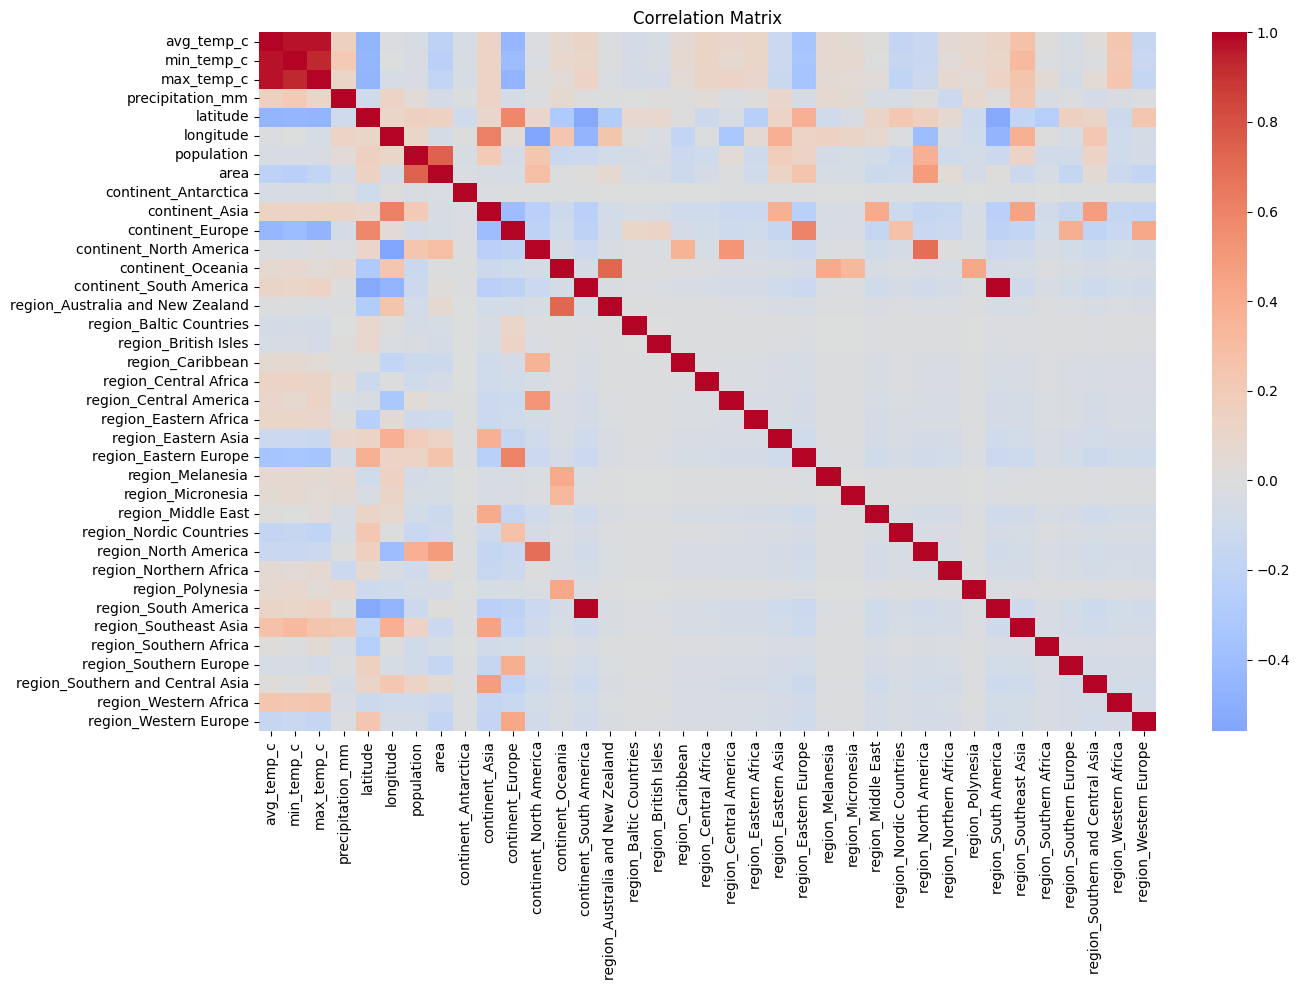

Correlation with avg_temp_c:
max_temp_c                 0.967039
min_temp_c                 0.966709
region_Southeast Asia      0.273368
region_Western Africa      0.235879
precipitation_mm           0.149748
continent_Asia             0.118227
region_Central Africa      0.118138
continent_South America    0.113824
region_South America       0.113824
region_Eastern Africa      0.109532
Name: avg_temp_c, dtype: float64


In [31]:
corr = data_ml.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, ax=ax)
plt.title('Correlation Matrix')
plt.tight_layout(); plt.show()

print('Correlation with avg_temp_c:')
print(corr['avg_temp_c'].drop('avg_temp_c').sort_values(ascending=False).head(10))

4. Train/test split — time-based

We set aside the most recent 20% of monthly records as the test set.

For time series data, a random split would be wrong. If we randomly mixed past and future records, the model could end up being trained on months from 2020 and tested on months from 2015 it would have already seen the future during training. The test set must always come strictly after the training set in time, so that the evaluation reflects what would happen when the model faces genuinely new, future data.

We sort by date first, then cut at the 80% row mark so training covers the earlier years and testing covers the most recent period.

In [32]:
# data is already sorted by date from the encode step
split = int(len(data_ml) * 0.8)
train = data_ml.iloc[:split]
test  = data_ml.iloc[split:]

X_train = train.drop(columns='avg_temp_c')
y_train = train['avg_temp_c']
X_test  = test.drop(columns='avg_temp_c')
y_test  = test['avg_temp_c']

print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (257596, 36) | Test: (64400, 36)


5. Feature scaling

We rescale every numeric column so they all live in the same range.

Latitude spans roughly -55 to 78, while population spans 3,000 to 1.3 billion. To a model doing arithmetic, population would appear overwhelmingly more important simply because its numbers are so much larger not because it is actually more useful for predicting temperature. Rescaling puts every column on equal footing so the model can judge them by their actual relationship to the target.

We fit the scaler on training data only so the test set is rescaled using exactly the same reference points, without the model ever seeing the test values during calibration.

In [33]:
scale_cols = X_train.select_dtypes(include='number').columns.tolist()

X_train[scale_cols] = X_train[scale_cols].astype(float)
X_test[scale_cols]  = X_test[scale_cols].astype(float)

scaler = StandardScaler()
X_train.loc[:, scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit on train only
X_test.loc[:, scale_cols]  = scaler.transform(X_test[scale_cols])

X_train[scale_cols].describe().round(2)   # mean ≈ 0, std ≈ 1

,min_temp_c,max_temp_c,precipitation_mm,latitude,longitude,population,area
count,257596.00,257596.00,257596.00,257596.00,257596.00,253206.00,256769.00
mean,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.99,-2.71,-0.90,-2.60,-2.10,-0.97,-0.89
25%,-0.68,-0.63,-0.81,-0.58,-0.44,-0.82,-0.73
50%,0.13,0.26,-0.36,0.32,0.03,-0.39,-0.47
75%,0.88,0.78,0.44,0.77,0.68,0.35,0.38
max,2.11,2.40,2.32,2.07,2.35,2.09,2.06


6. Final sanity check

We run a final check to confirm the data is fully ready before it reaches a model.

A silent error a text column that slipped through encoding, or a single NaN that survived all the cleaning steps could corrupt the training process in a way that produces strange results with no obvious explanation. Catching it here with a loud, clear error message is far faster than debugging a model that is quietly producing wrong predictions.

We use assert statements that immediately stop execution and print a descriptive message the moment any condition fails.

In [ ]:
assert not X_train.isnull().any().any(), 'NaN in train!'
assert not X_test.isnull().any().any(),  'NaN in test!'
assert all(X_train.dtypes != object),    'Non-numeric column!'

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Data is ML-ready.')

---

# Further Reading

- Pandas time series: [https://pandas.pydata.org/docs/user_guide/timeseries.html](https://pandas.pydata.org/docs/user_guide/timeseries.html)
- Resampling: [https://pandas.pydata.org/docs/reference/resampling.html](https://pandas.pydata.org/docs/reference/resampling.html)
- Scikit-learn TimeSeriesSplit: [https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)